In [3]:
import pandas as pd
import numpy as mp
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten,Dense,Conv2D,MaxPooling2D,Dropout
from sklearn.model_selection import train_test_split


In [4]:
train_data=pd.read_csv(r"F:\lp4\LP IV Updated Datasets\FNN and CNN\HandWritten MNIST\mnist_train.csv")
test_data=pd.read_csv(r"F:\lp4\LP IV Updated Datasets\FNN and CNN\HandWritten MNIST\mnist_test.csv")



In [50]:
x_train=train_data.drop('label',axis=1).values
x_test=test_data.drop('label',axis=1).values

y_train=train_data['label'].values
y_test=test_data['label'].values

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(60000, 784)
(10000, 784)
(60000,)
(10000,)


In [51]:
x_train=x_train.reshape(-1,28,28,1)
x_test=x_test.reshape(-1,28,28,1)
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [52]:
x_train=x_train.astype('float32')/255.0
x_test=x_test.astype('float32')/255.0
print(x_train.shape)
print(x_test.shape)



(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [53]:
model=Sequential([
    Conv2D(28,(1,1),activation='relu',input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Conv2D(56,(1,1),activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(112,activation='relu'),
    Dropout(0.5),
    Dense(10,activation='softmax')
    
])

C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


model.summary()

In [54]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)                   │ (None, 28, 28, 28)          │              56 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 14, 14, 28)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 14, 14, 56)          │           1,624 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_11 (MaxPooling2D)      │ (None, 7, 7, 56)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 2744)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 112)                 │         307,440 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 112)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 10)                  │           1,130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 310,250 (1.18 MB)

 Trainable params: 310,250 (1.18 MB)

 Non-trainable params: 0 (0.00 B)

In [56]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [57]:
history=model.fit(
    x_train,y_train,epochs=5,batch_size=28,validation_split=0.1
)

Epoch 1/5
1929/1929 ━━━━━━━━━━━━━━━━━━━━ 40s 18ms/step - accuracy: 0.7801 - loss: 0.6851 - val_accuracy: 0.8922 - val_loss: 0.3232
Epoch 2/5
1929/1929 ━━━━━━━━━━━━━━━━━━━━ 37s 19ms/step - accuracy: 0.8394 - loss: 0.5009 - val_accuracy: 0.9130 - val_loss: 0.2678
Epoch 3/5
1929/1929 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - accuracy: 0.8594 - loss: 0.4411 - val_accuracy: 0.9198 - val_loss: 0.2405
Epoch 4/5
1929/1929 ━━━━━━━━━━━━━━━━━━━━ 39s 20ms/step - accuracy: 0.8733 - loss: 0.3996 - val_accuracy: 0.9325 - val_loss: 0.2065
Epoch 5/5
1929/1929 ━━━━━━━━━━━━━━━━━━━━ 36s 19ms/step - accuracy: 0.8824 - loss: 0.3741 - val_accuracy: 0.9395 - val_loss: 0.1959


In [59]:
test_loss,test_accuracy=model.evalute(x_test,y_test)

AttributeError: 'Sequential' object has no attribute 'evalute'

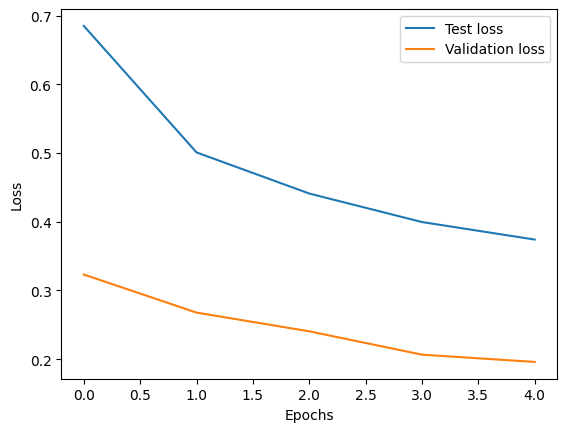

In [60]:
plt.plot(history.history['loss'],label='Test loss')
plt.plot(history.history['val_loss'],label='Validation loss')
plt.legend()
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()


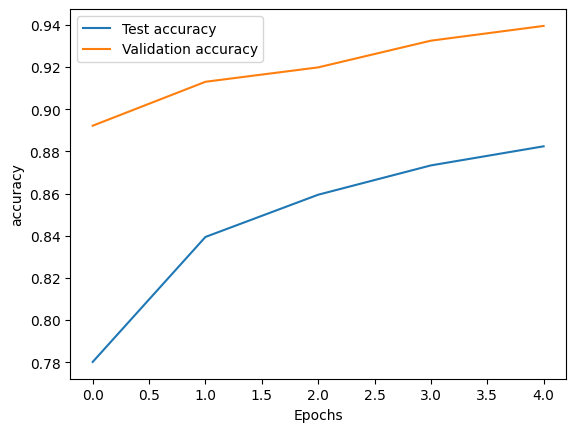

In [61]:
plt.plot(history.history['accuracy'],label='Test accuracy')
plt.plot(history.history['val_accuracy'],label='Validation accuracy')
plt.legend()
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.show()


In [62]:

# PRACTICAL 2B: CNN FOR HANDWRITTEN MNIST CLASSIFICATION

# --------------------------------------------------
# STAGE A: LOADING AND PREPROCESSING IMAGE DATA
# --------------------------------------------------

# 1. Import libraries

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)


# 2. Load training and testing datasets

train_data = pd.read_csv(
    r"F:\lp4\LP IV Updated Datasets\FNN and CNN\HandWritten MNIST\mnist_train.csv"
)

test_data = pd.read_csv(
    r"F:\lp4\LP IV Updated Datasets\FNN and CNN\HandWritten MNIST\mnist_test.csv"
)


# 3. Separate features and labels

x_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

x_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values


# 4. Reshape images

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)


# 5. Normalize pixel values

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0


# 6. Display dataset information

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

print("Labels:", np.unique(y_train))
print("Pixel range:", x_train.min(), x_train.max())


# --------------------------------------------------
# STAGE B: DEFINING MODEL ARCHITECTURE
# --------------------------------------------------

model = Sequential([

    Input(shape=(28, 28, 1)),

    # First Convolutional Layer
    Conv2D(32, (3, 3), activation='relu'),

    # First Pooling Layer
    MaxPooling2D((2, 2)),

    # Second Convolutional Layer
    Conv2D(64, (3, 3), activation='relu'),

    # Second Pooling Layer
    MaxPooling2D((2, 2)),

    # Flatten Layer
    Flatten(),

    # Fully Connected Layer
    Dense(128, activation='relu'),

    # Dropout Layer
    Dropout(0.5),

    # Output Layer
    Dense(10, activation='softmax')
])


# Display model architecture

model.summary()


# --------------------------------------------------
# STAGE C: TRAINING THE MODEL
# --------------------------------------------------

# 1. Compile the model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


# 2. Train the model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)


# --------------------------------------------------
# STAGE D: ESTIMATING MODEL PERFORMANCE
# --------------------------------------------------

# 1. Evaluate the model

test_loss, test_accuracy = model.evaluate(
    x_test, y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


# 2. Plot training and validation loss

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()


# 3. Plot training and validation accuracy

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()


# 4. Predict handwritten digits

predictions = model.predict(x_test[:5])

for i in range(5):

    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {y_test[i]}, Predicted: {np.argmax(predictions[i])}"
    )

    plt.axis('off')
    plt.show()


MemoryError: Unable to allocate 179. MiB for an array with shape (60000, 28, 28, 1) and data type float32